# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** *Pirathishanth*  
**Index number:** *220480P*  
**GitHub  :** https://github.com/pirathi2002/EN4554-Assignment-2-Convolutional-Neural-Networks

---

### Contents
| Part | Topic | Rough run time on a Colab T4 |
|---|---|---|
| Setup | Data, utilities | 1 min |
| Task 1 | Backpropagation from scratch (Linear / ReLU / softmax-CE), gradient checks, MLP training, vanishing gradients | ~5 min |
| Task 2 | Own SGD-momentum and Adam, behaviour on an ill-conditioned quadratic, optimiser / learning-rate sweep on a CNN | ~15 min |
| Task 3 | Regularisation study on 5k images; plain vs residual networks of depth 8 / 20 / 56 | ~60–90 min |
| Task 4 (optional) | Best CNN with ≤ 500k parameters and ≤ 20 epochs, ablation, one-shot test evaluation | ~30 min |

### Use of AI tools (required acknowledgement)
I used Claude (Anthropic) to help generate the initial code structure and the interpretation drafts of this notebook. I ran all the experiments myself on a Colab T4, checked the interpretations against my own results, and I understand the code.

In [22]:
import os, time, math, random, json, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

QUICK = False          # True -> tiny subsets + 1-2 epochs: a smoke test of the whole notebook
QUICK_N = (3000, 600)  # (#train, #val) used in QUICK mode
SEED = 42

def E(full, quick=1):
    """Number of epochs: `full` normally, `quick` in QUICK mode."""
    return quick if QUICK else full

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('torch', torch.__version__, '| device:', device, '| QUICK =', QUICK)

torch 2.11.0+cu130 | device: cuda | QUICK = False


## 0. Data: CIFAR-10, 45k / 5k split, per-channel normalisation

* The 50,000 official training images are split (fixed seed) into **45,000 train / 5,000 validation**.
* Each colour channel is normalised with the **mean / std of the 45k training images only** (no leakage from validation or test).
* The official 10,000-image **test set is not loaded here**; it is touched exactly once, at the very end of Task 4.
* The whole dataset is kept as tensors on the GPU, so training loops are fast and augmentation is done on the GPU as well.

train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean [0.4917 0.4823 0.4467] | std [0.2471 0.2435 0.2616]
train class counts [4512, 4488, 4468, 4529, 4529, 4486, 4493, 4500, 4496, 4499]
val   class counts [488, 512, 532, 471, 471, 514, 507, 500, 504, 501]


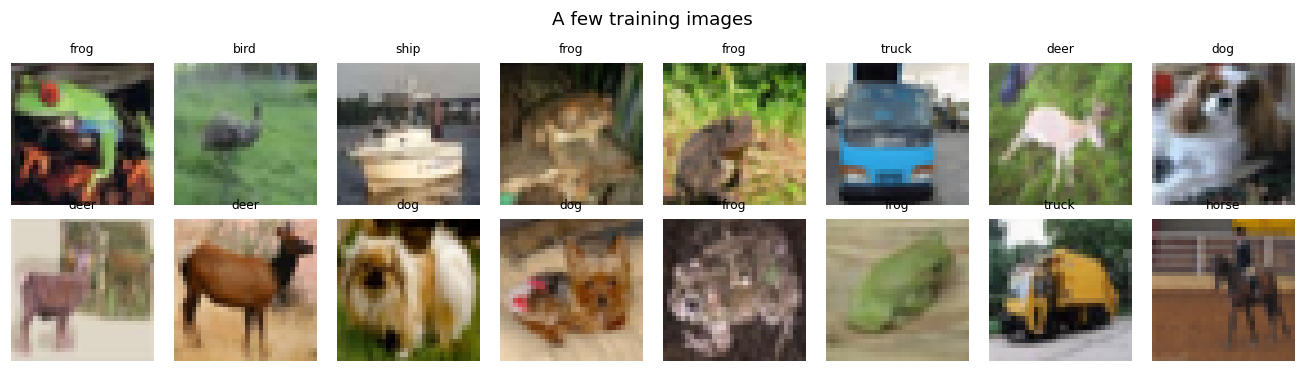

In [23]:
tv_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
CLASSES = tv_train.classes
X_u8 = torch.from_numpy(tv_train.data).permute(0, 3, 1, 2).contiguous()      # (50000,3,32,32) uint8
y_all = torch.tensor(tv_train.targets)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_u8), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]
if QUICK:
    tr_idx, va_idx = tr_idx[:QUICK_N[0]], va_idx[:QUICK_N[1]]

Xtr_raw = X_u8[tr_idx].float().div(255)
mean = Xtr_raw.mean((0, 2, 3), keepdim=True)          # per-channel statistics of the TRAINING split only
std  = Xtr_raw.std((0, 2, 3), keepdim=True)
Xtr = ((Xtr_raw - mean) / std).to(device); ytr = y_all[tr_idx].to(device)
Xva = ((X_u8[va_idx].float().div(255) - mean) / std).to(device); yva = y_all[va_idx].to(device)
del Xtr_raw
mean_d, std_d = mean.to(device), std.to(device)
def denorm(x): return (x * std_d + mean_d).clamp(0, 1)

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean', mean.flatten().numpy().round(4), '| std', std.flatten().numpy().round(4))
print('train class counts', torch.bincount(ytr.cpu(), minlength=10).tolist())
print('val   class counts', torch.bincount(yva.cpu(), minlength=10).tolist())

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(denorm(Xtr[i:i+1])[0].permute(1, 2, 0).cpu()); a.set_title(CLASSES[ytr[i]], fontsize=8); a.axis('off')
plt.suptitle('A few training images'); plt.tight_layout(); plt.show()

## Shared utilities
`evaluate` (loss / accuracy in eval mode) and `train_model` (a generic training loop that supports GPU augmentation, mixup, label smoothing, a per-step LR scheduler, and records per-epoch curves). Everything later reuses these.

In [24]:
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    """Mean cross-entropy and accuracy of `model` (eval mode) on (X, y)."""
    was_training = model.training; model.eval()
    tot, ok = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i+bs])
        tot += F.cross_entropy(out, y[i:i+bs], reduction='sum').item()
        ok += (out.argmax(1) == y[i:i+bs]).sum().item()
    model.train(was_training)
    return tot / len(X), ok / len(X)

def warmup_cosine(opt, total_steps, warmup_steps=0):
    """Linear warm-up followed by cosine decay to 0; call .step() once per iteration."""
    def f(s):
        if s < warmup_steps: return (s + 1) / warmup_steps
        pr = (s - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * pr))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train_model(model, opt, epochs, Xt, yt, Xv, yv, bs=128, augment=None, mixup_alpha=0.0,
                scheduler=None, label_smoothing=0.0, eval_train=False, tag='', log_every=None):
    """Generic training loop. Returns a dict of per-epoch curves.
    train_loss : running mean of the (possibly augmented / mixed) minibatch loss during the epoch
    train_acc  : accuracy on the CLEAN training set in eval mode if eval_train else running accuracy
    val_*      : clean validation loss / accuracy in eval mode
    """
    model.to(device)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time']}
    hist['diverged'] = False
    n = len(Xt); nb = n // bs                       # drop the last incomplete batch (a new shuffle each epoch)
    log_every = log_every or max(1, epochs // 5)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=Xt.device)
        run_loss = torch.zeros((), device=Xt.device); run_ok = torch.zeros((), device=Xt.device)
        for k in range(nb):
            b = perm[k*bs:(k+1)*bs]
            xb, yb = Xt[b], yt[b]
            if augment is not None: xb = augment(xb)
            if mixup_alpha > 0:                     # mixup: convex combination of two minibatches / label sets
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                p = torch.randperm(len(xb), device=xb.device)
                out = model(lam * xb + (1 - lam) * xb[p])
                loss = lam * F.cross_entropy(out, yb, label_smoothing=label_smoothing) \
                     + (1 - lam) * F.cross_entropy(out, yb[p], label_smoothing=label_smoothing)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if scheduler is not None: scheduler.step()
            run_loss += loss.detach() * len(b); run_ok += (out.argmax(1) == yb).sum()
        tl = run_loss.item() / (nb * bs)
        ta = evaluate(model, Xt, yt)[1] if eval_train else run_ok.item() / (nb * bs)
        vl, va = evaluate(model, Xv, yv)
        for k_, v_ in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time'], [tl, ta, vl, va, time.time() - t0]):
            hist[k_].append(v_)
        if (ep + 1) % log_every == 0 or ep == 0 or ep == epochs - 1:
            print(f'[{tag}] ep {ep+1:3d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:5.0f}s')
        if not math.isfinite(tl):
            hist['diverged'] = True; print(f'[{tag}] diverged (loss = {tl}) - stopping early'); break
    return hist

# Task 3 – Regularisation and residual connections

## 3(a) Regularisation on a small training set (5k images)

**Set-up.** A small CNN **with batch norm** (3 stages × [conv-BN-ReLU] × 2, widths 32/64/128, ≈0.31M parameters) is trained on **5,000 training images** (random subset of the 45k) and evaluated on the **full 5k validation set**. Every configuration uses the same architecture, seed / initial weights, optimiser (SGD, momentum 0.9, lr 0.02, 2-epoch linear warm-up then cosine decay to 0, batch 128) and number of epochs; only the regulariser changes:

| name | what is switched on |
|---|---|
| baseline | nothing |
| weight decay | L2 penalty 5e-4 |
| dropout | `Dropout(0.3)` after every pooling stage |
| flip+crop | random horizontal flip + random 32×32 crop from the 4-pixel zero-padded image |
| cutout | one random 16×16 square set to 0 (= the dataset mean after normalisation) |
| mixup | $\tilde x=\lambda x_i+(1-\lambda)x_j$, loss $\lambda\,\ell(f(\tilde x),y_i)+(1-\lambda)\,\ell(f(\tilde x),y_j)$, $\lambda\sim\mathrm{Beta}(0.4,0.4)$ |
| all combined | weight decay + dropout + flip/crop + cutout + mixup |

**Cutout, mixup (in `train_model`), flip and crop are implemented by hand below**; all augmentations run on the GPU.

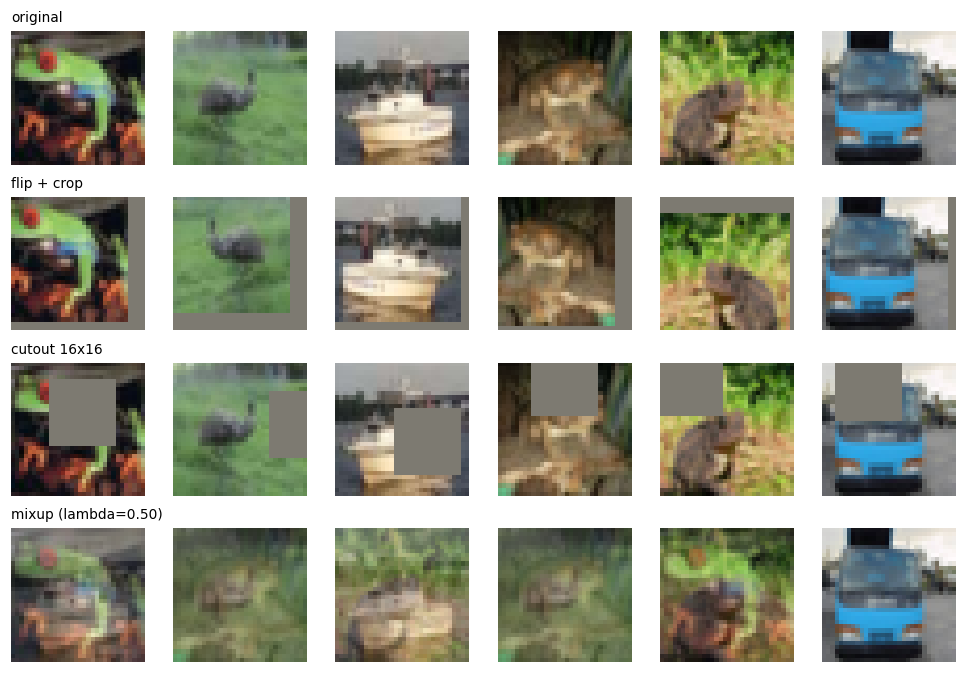

In [34]:
def random_crop_flip(x, pad=4):
    """Random horizontal flip (p=0.5) + random crop of the zero-padded image, independently for every sample."""
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad,) * 4)                                           # (N, C, H+2p, W+2p)
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = i[:, None] + torch.arange(H, device=x.device)[None]          # (N, H)
    cols = j[:, None] + torch.arange(W, device=x.device)[None]          # (N, W)
    out = xp[torch.arange(N, device=x.device)[:, None, None], :, rows[:, :, None], cols[:, None, :]]   # (N, H, W, C)
    return out.permute(0, 3, 1, 2).contiguous()

def cutout(x, size=16):
    """Zero out one size x size square per image; the centre is uniform over the image, the square is clipped at the border."""
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N, 1, 1), device=x.device); cx = torch.randint(0, W, (N, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]; xs = torch.arange(W, device=x.device)[None, None, :]
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)   # (N, H, W)
    return x * (~hole).unsqueeze(1).to(x.dtype)

def mixup_batch(x, y, alpha=0.4):
    """(Same logic as inside train_model, exposed here for visualisation.)  Returns mixed x, y_a, y_b, lambda."""
    lam = float(np.random.beta(alpha, alpha)); p = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[p], y, y[p], lam

# --- visualise the augmentations (sanity check of our implementations)
set_seed()
xs_ = Xtr[:6]
mx, ya, yb_, lam = mixup_batch(xs_, ytr[:6], alpha=1.0)
rows_ = [('original', xs_), ('flip + crop', random_crop_flip(xs_)), ('cutout 16x16', cutout(xs_)), (f'mixup (lambda={lam:.2f})', mx)]
fig, ax = plt.subplots(4, 6, figsize=(9, 6.2))
for r, (t, imgs) in enumerate(rows_):
    for c in range(6):
        ax[r, c].imshow(denorm(imgs[c:c+1])[0].permute(1, 2, 0).cpu()); ax[r, c].axis('off')
    ax[r, 0].set_title(t, fontsize=9, loc='left')
plt.tight_layout(); plt.show()

In [43]:
N_SMALL = min(5000, len(Xtr))
sub = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(SEED))[:N_SMALL].to(device)
Xs, ys_ = Xtr[sub], ytr[sub]
print('small training set:', tuple(Xs.shape), '| class counts', torch.bincount(ys_.cpu(), minlength=10).tolist())

AUG_ALL = lambda x: cutout(random_crop_flip(x), 16)
CONFIGS = {
    'baseline':     dict(wd=0.0,  p_drop=0.0, aug=None,             mixup=0.0),
    'weight decay': dict(wd=5e-4, p_drop=0.0, aug=None,             mixup=0.0),
    'dropout':      dict(wd=0.0,  p_drop=0.3, aug=None,             mixup=0.0),
    'flip+crop':    dict(wd=0.0,  p_drop=0.0, aug=random_crop_flip, mixup=0.0),
    'cutout':       dict(wd=0.0,  p_drop=0.0, aug=cutout,           mixup=0.0),
    'mixup':        dict(wd=0.0,  p_drop=0.0, aug=None,             mixup=0.4),
    'all combined': dict(wd=5e-4, p_drop=0.3, aug=AUG_ALL,          mixup=0.4),
}
EPOCHS_3A, BS_3A = E(60, 2), 128
res3a = {}
for name, cfg in CONFIGS.items():
    set_seed()
    model = SmallCNN(widths=(32, 64, 128), convs=2, bn=True, p_drop=cfg['p_drop']).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.02, momentum=0.9, weight_decay=cfg['wd'])
    spe = N_SMALL // BS_3A
    sched = warmup_cosine(opt, EPOCHS_3A * spe, warmup_steps=2 * spe)
    res3a[name] = train_model(model, opt, EPOCHS_3A, Xs, ys_, Xva, yva, bs=BS_3A, augment=cfg['aug'], mixup_alpha=cfg['mixup'],
                              scheduler=sched, eval_train=True, tag=name, log_every=max(1, EPOCHS_3A // 3))

small training set: (5000, 3, 32, 32) | class counts [496, 527, 496, 466, 475, 513, 487, 495, 533, 512]
[baseline] ep   1/60 | train loss 2.057 acc 0.432 | val loss 1.865 acc 0.376 |     1s
[baseline] ep  20/60 | train loss 0.004 acc 1.000 | val loss 1.384 acc 0.640 |    25s
[baseline] ep  40/60 | train loss 0.002 acc 1.000 | val loss 1.437 acc 0.642 |    50s
[baseline] ep  60/60 | train loss 0.002 acc 1.000 | val loss 1.447 acc 0.643 |    75s
[weight decay] ep   1/60 | train loss 2.057 acc 0.438 | val loss 1.850 acc 0.380 |     1s
[weight decay] ep  20/60 | train loss 0.005 acc 1.000 | val loss 1.355 acc 0.630 |    25s
[weight decay] ep  40/60 | train loss 0.003 acc 1.000 | val loss 1.369 acc 0.633 |    50s
[weight decay] ep  60/60 | train loss 0.003 acc 1.000 | val loss 1.372 acc 0.633 |    75s
[dropout] ep   1/60 | train loss 2.356 acc 0.324 | val loss 1.970 acc 0.305 |     1s
[dropout] ep  20/60 | train loss 0.730 acc 0.779 | val loss 1.198 acc 0.613 |    25s
[dropout] ep  40/60 | 

configuration   train acc   val acc  gap (train-val)  best val acc  val loss
baseline           1.0000    0.6430           0.3570        0.6444     1.447
weight decay       1.0000    0.6326           0.3674        0.6348     1.372
dropout            0.9854    0.6808           0.3046        0.6896     1.064
flip+crop          0.9802    0.7340           0.2462        0.7348     0.904
cutout             1.0000    0.6730           0.3270        0.6740     1.399
mixup              1.0000    0.6214           0.3786        0.6264     1.143
all combined       0.6656    0.6140           0.0516        0.6160     1.094


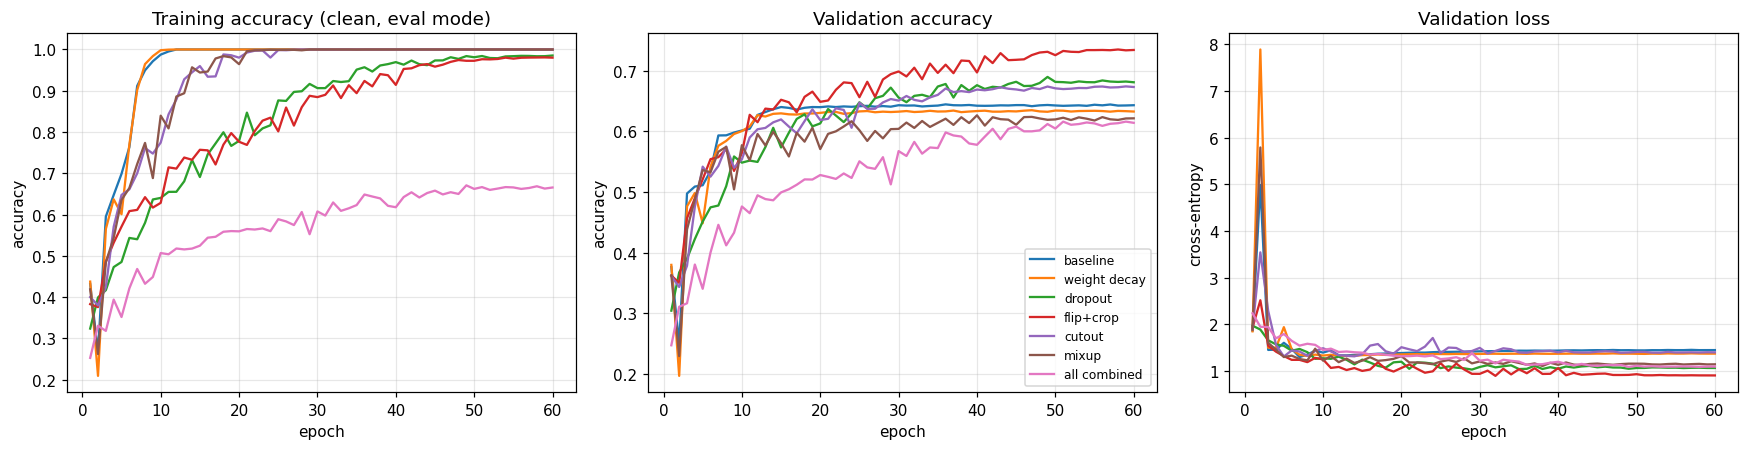

In [44]:
print(f"{'configuration':14s}{'train acc':>11s}{'val acc':>10s}{'gap (train-val)':>17s}{'best val acc':>14s}{'val loss':>10s}")
for name, h in res3a.items():
    ta, va = h['train_acc'][-1], h['val_acc'][-1]
    print(f"{name:14s}{ta:11.4f}{va:10.4f}{ta - va:17.4f}{max(h['val_acc']):14.4f}{h['val_loss'][-1]:10.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for k, (name, h) in enumerate(res3a.items()):
    ep = range(1, len(h['val_acc']) + 1); ls = '-' if k < 7 else '--'
    ax[0].plot(ep, h['train_acc'], ls, label=name); ax[1].plot(ep, h['val_acc'], ls, label=name); ax[2].plot(ep, h['val_loss'], ls, label=name)
for a, t, yl in zip(ax, ['Training accuracy (clean, eval mode)', 'Validation accuracy', 'Validation loss'], ['accuracy', 'accuracy', 'cross-entropy']):
    a.set_title(t); a.set_xlabel('epoch'); a.set_ylabel(yl)
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation (3a).** The **baseline** memorises the 5k training images (clean training accuracy 100%) but reaches only 64.3% validation accuracy, a generalisation gap of 35.7 points, and its validation loss (1.447) is high because the network is over-confident on wrong predictions. **Flip+crop** is clearly the best single regulariser: validation accuracy rises to 73.4% (+9.1 points), the gap shrinks to 24.6 points and the validation loss falls to 0.904. Data augmentation helps most because with only 5k images the network cannot learn the translation and mirror invariances by itself, and each augmented view acts as a new training example. **Dropout** gives a smaller gain (68.1%, +3.8 points, gap 30.4) and **cutout** a small one (67.3%, +3.0 points); cutout still reaches 100% training accuracy, so the 16×16 occlusion alone is not hard enough to stop memorisation of the clean images. **Weight decay** (63.3%) is no better than the baseline: the 1-point difference is within single-seed noise. This is expected, since with batch norm the scale of the convolution weights does not change the function, so L2 only changes the effective learning rate rather than reducing capacity. **Mixup** gives the lowest accuracy (62.1%, −2.2 points) but a much lower validation loss than the baseline (1.143 vs 1.447). It does not improve accuracy here, but it makes the predictions less over-confident (better calibrated), since mixed targets discourage confident outputs. **All combined** is under-fitted after 60 epochs: its clean training accuracy is only 66.6% and validation accuracy is 61.4%, so the gap is just 5.2 points, but both are still rising (validation loss 1.316 → 1.197 → 1.094) when training ends. Strong regularisation slows fitting, so with a fixed epoch budget it loses to flip+crop alone, and it would probably need many more epochs to benefit. Overall, the most useful regulariser for this small dataset is data augmentation (flip+crop), and combining all regularisers is not automatically better without a longer training schedule. Caveat: one seed per configuration, so differences of about 1 point (for example baseline vs weight decay) should not be over-interpreted.

## 3(b) Plain vs residual networks of depth 6n + 2 (8, 20, 56)

CIFAR-style networks as in He et al.: a 3×3 conv (16 channels) → 3 stages of $n$ basic blocks with 16 / 32 / 64 channels (stride 2 at the start of stages 2 and 3) → global average pooling → linear layer; batch norm after every convolution, **Kaiming initialisation** for all conv / linear layers. Depth $=6n+2$ → $n=1,3,9$.

The **only** difference between the two families is the shortcut: a basic block is
* plain: $y=\mathrm{ReLU}(\mathrm{BN}(\mathrm{conv}(\mathrm{ReLU}(\mathrm{BN}(\mathrm{conv}(x))))))$,
* residual: $y=\mathrm{ReLU}(\mathrm{BN}(\mathrm{conv}(\cdots))+\text{shortcut}(x))$, where the shortcut is the identity, or – where the resolution / width changes – a **parameter-free** option-A shortcut (stride-2 subsampling + zero-padding of channels). Hence plain and residual networks have **exactly the same number of parameters**.

Training (identical for all six models): SGD momentum 0.9, lr 0.1 (1 epoch linear warm-up, then cosine decay), weight decay 1e-4, batch 128, flip+crop augmentation, 45k training images.

In [37]:
class Shortcut(nn.Module):
    """Option-A shortcut: stride-2 subsampling and zero-padding of the channels (no parameters)."""
    def __init__(self, planes): super().__init__(); self.pad = planes // 4
    def forward(self, x): return F.pad(x[:, :, ::2, ::2], (0, 0, 0, 0, self.pad, self.pad))

class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.shortcut = Shortcut(cout) if (residual and (stride != 1 or cin != cout)) else nn.Identity()
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual: out = out + self.shortcut(x)                 # <- the ONLY difference between the two families
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, depth, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0, 'depth must be 6n+2'
        n = (depth - 2) // 6
        self.conv1 = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False); self.bn1 = nn.BatchNorm2d(widths[0])
        blocks, cin = [], widths[0]
        for s, w in enumerate(widths):
            for b in range(n):
                blocks.append(BasicBlock(cin, w, 2 if (s > 0 and b == 0) else 1, residual)); cin = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():                                         # Kaiming initialisation
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.Linear): nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.adaptive_avg_pool2d(self.blocks(x), 1).flatten(1)
        return self.fc(x)

# sanity checks: number of weight layers = depth, and plain / residual have identical parameter counts
for d in (8, 20, 56):
    p_, r_ = CifarNet(d, False), CifarNet(d, True)
    n_layers = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in r_.modules())
    print(f'depth {d:2d}: weight layers = {n_layers:2d} | params plain = {count_params(p_):,} | residual = {count_params(r_):,}')
    assert count_params(p_) == count_params(r_)

depth  8: weight layers =  8 | params plain = 75,290 | residual = 75,290
depth 20: weight layers = 20 | params plain = 269,722 | residual = 269,722
depth 56: weight layers = 56 | params plain = 853,018 | residual = 853,018


In [38]:
EPOCHS_3B, BS_3B = E(15, 1), 128
DEPTHS = [8, 20, 56]
res3b = {}
for depth in DEPTHS:
    for residual in (False, True):
        name = f"{'residual' if residual else 'plain'}-{depth}"
        set_seed()
        model = CifarNet(depth, residual).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
        spe = len(Xtr) // BS_3B
        sched = warmup_cosine(opt, EPOCHS_3B * spe, warmup_steps=spe)
        res3b[name] = train_model(model, opt, EPOCHS_3B, Xtr, ytr, Xva, yva, bs=BS_3B, augment=random_crop_flip,
                                  scheduler=sched, tag=name, log_every=max(1, EPOCHS_3B // 3))

[plain-8] ep   1/15 | train loss 1.689 acc 0.376 | val loss 1.960 acc 0.362 |     4s
[plain-8] ep   5/15 | train loss 0.834 acc 0.705 | val loss 0.853 acc 0.704 |    21s
[plain-8] ep  10/15 | train loss 0.604 acc 0.791 | val loss 0.624 acc 0.778 |    41s
[plain-8] ep  15/15 | train loss 0.506 acc 0.827 | val loss 0.524 acc 0.817 |    62s
[residual-8] ep   1/15 | train loss 1.689 acc 0.383 | val loss 2.036 acc 0.370 |     4s
[residual-8] ep   5/15 | train loss 0.839 acc 0.706 | val loss 1.003 acc 0.672 |    22s
[residual-8] ep  10/15 | train loss 0.607 acc 0.790 | val loss 0.644 acc 0.775 |    44s
[residual-8] ep  15/15 | train loss 0.512 acc 0.824 | val loss 0.535 acc 0.809 |    65s
[plain-20] ep   1/15 | train loss 1.821 acc 0.303 | val loss 2.604 acc 0.274 |    12s
[plain-20] ep   5/15 | train loss 0.817 acc 0.713 | val loss 0.843 acc 0.707 |    58s
[plain-20] ep  10/15 | train loss 0.530 acc 0.816 | val loss 0.588 acc 0.799 |   116s
[plain-20] ep  15/15 | train loss 0.392 acc 0.866 

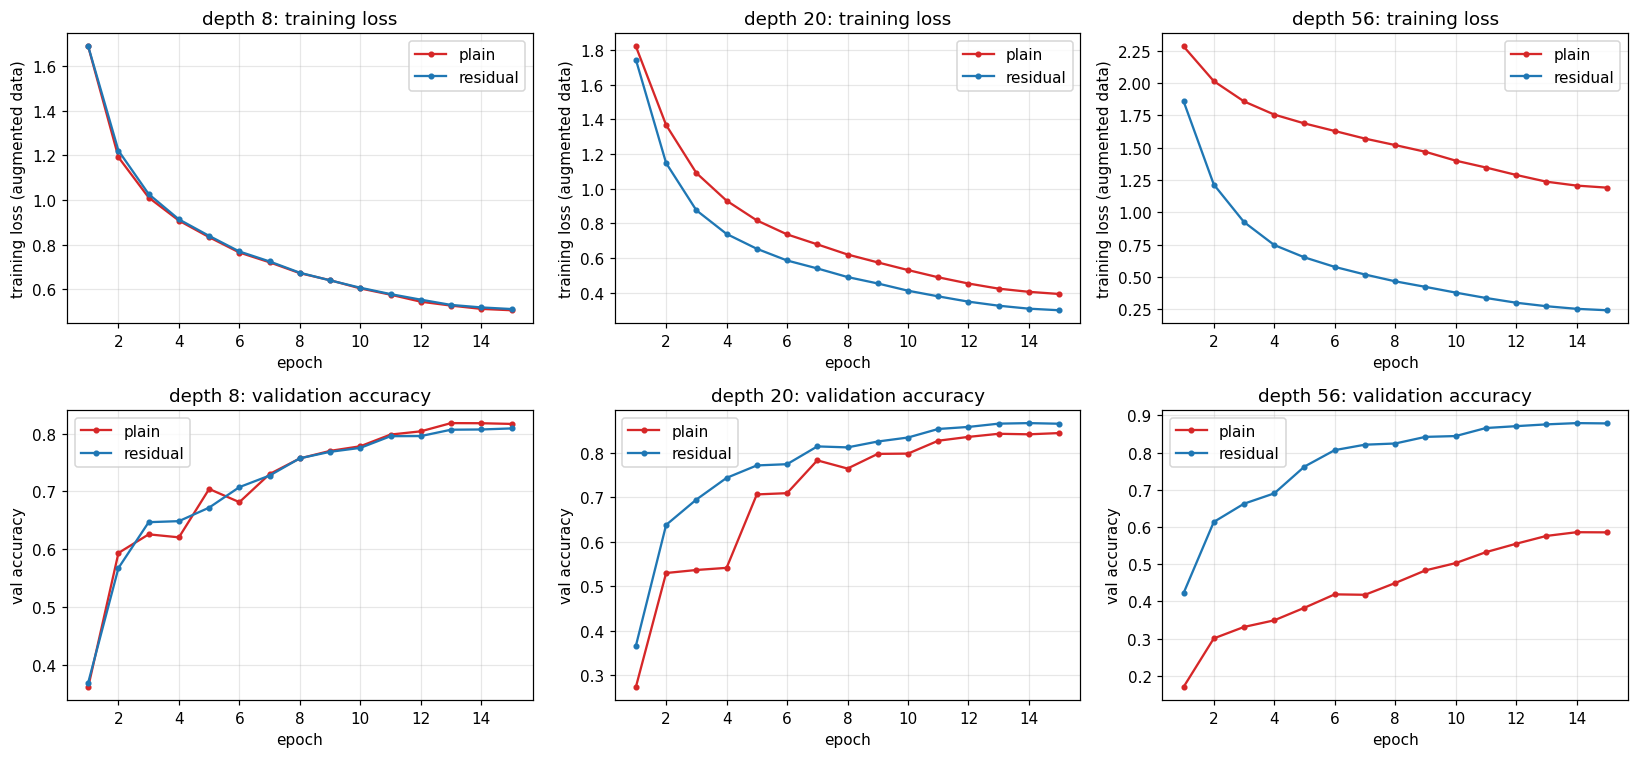

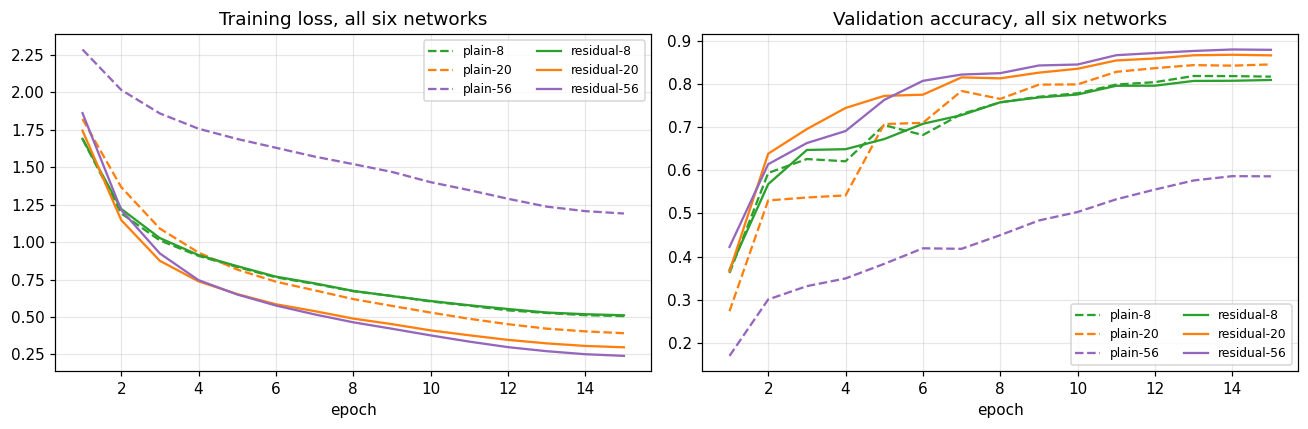

network           params  final train loss  final val acc  time (s)
plain-8           75,290            0.5062         0.8166        62
residual-8        75,290            0.5116         0.8088        65
plain-20         269,722            0.3919         0.8448       174
residual-20      269,722            0.2980         0.8658       182
plain-56         853,018            1.1908         0.5858       510
residual-56      853,018            0.2408         0.8786       532


In [39]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for c, depth in enumerate(DEPTHS):
    for fam, col in (('plain', 'C3'), ('residual', 'C0')):
        h = res3b[f'{fam}-{depth}']; ep = range(1, len(h['train_loss']) + 1)
        ax[0, c].plot(ep, h['train_loss'], 'o-', color=col, ms=3, label=fam)
        ax[1, c].plot(ep, h['val_acc'], 'o-', color=col, ms=3, label=fam)
    ax[0, c].set_title(f'depth {depth}: training loss'); ax[0, c].set_xlabel('epoch'); ax[0, c].set_ylabel('training loss (augmented data)'); ax[0, c].legend()
    ax[1, c].set_title(f'depth {depth}: validation accuracy'); ax[1, c].set_xlabel('epoch'); ax[1, c].set_ylabel('val accuracy'); ax[1, c].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for fam, ls_ in (('plain', '--'), ('residual', '-')):
    for depth, col in zip(DEPTHS, ['C2', 'C1', 'C4']):
        h = res3b[f'{fam}-{depth}']
        ax[0].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], ls_, color=col, label=f'{fam}-{depth}')
        ax[1].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], ls_, color=col, label=f'{fam}-{depth}')
ax[0].set_title('Training loss, all six networks'); ax[1].set_title('Validation accuracy, all six networks')
for a in ax: a.set_xlabel('epoch'); a.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

print(f"{'network':14s}{'params':>10s}{'final train loss':>18s}{'final val acc':>15s}{'time (s)':>10s}")
for name, h in res3b.items():
    d = int(name.split('-')[1]); fam = name.split('-')[0]
    print(f"{name:14s}{count_params(CifarNet(d, fam=='residual')):10,d}{h['train_loss'][-1]:18.4f}{h['val_acc'][-1]:15.4f}{h['time'][-1]:10.0f}")

**Interpretation (3b).** At depth 8 the plain and residual networks behave almost identically (final training loss 0.506 vs 0.512, validation accuracy 81.7% vs 80.9%, a difference within noise), because there is little to optimise. At depth 20 the residual network is already better (training loss 0.298 vs 0.392, validation accuracy 86.6% vs 84.5%). At depth 56 the difference is dramatic: the plain network reaches a training loss of 1.19 and only 58.6% validation accuracy, and its first epoch is stuck near chance (loss 2.285 ≈ ln 10), while the residual network reaches a training loss of 0.24 and 87.9%. The plain 56-layer network has a *higher training loss* than the plain 20-layer one, so this is not over-fitting. It is the degradation (optimisation) problem described by He et al.: the deeper plain network could in principle represent the shallower one (extra layers as identity), but SGD does not find such a solution in the same number of epochs, even with batch norm and Kaiming init. With shortcuts the training loss decreases with depth (0.512 → 0.298 → 0.241), because the identity path gives gradients a direct route (∂y/∂x = I + ∂F/∂x) and each block only needs to learn a small residual. Plain and residual nets have identical parameter counts and nearly identical time (about 4, 12 and 35 s per epoch for depths 8, 20 and 56), so the gain costs nothing.